In [4]:
from google.colab import drive

drive.flush_and_unmount()
drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
from pathlib import Path

paths = [
    Path("/content/drive"),
    Path("/content/drive/MyDrive"),
    Path("/content/drive/MyDrive/uni"),
    Path("/content/drive/MyDrive/uni/applied_deep_learning"),
]

for path in paths:
    print(f"\n{path} — exists: {path.is_dir()}")
    if path.is_dir():
        print([p.name for p in path.iterdir()])


/content/drive — exists: True
['.shortcut-targets-by-id', 'MyDrive', 'Othercomputers', '.Trash-0', '.Encrypted']

/content/drive/MyDrive — exists: True
['Meine gespeicherten Orte.gmap', 'Unbenanntes Dokument (1).gdoc', 'ZeittafelGeschichte.pdf', 'Unbenannte Präsentation.gslides', '4.1-4.2-4.3-4.4  ECOLOGÃ\x8dA  - 5.1-5.2 EVOLUCIÃ\x93N.ppt', 'Lebenslauf.gdoc', 'Kopie von Official TimelineJS3 Template\n.gsheet', 'Fotos de la reunion esa', 'Palabras Costeñas.gsheet', 'AMACAS Band.docx', 'AMACAS Band (1).gdoc', 'AMACAS Band.gdoc', 'new stars ablauf.xlsx', 'New Stars Ablauf.xlsx', 'SFWindenfahrer.pdf', 'SFWindenfahrer.gdoc', 'MoneyManager', 'VID_20221030_121602.mp4', 'VID_20221030_121539.mp4', 'Antrag AE mit RGL Januar 2020[1945].doc', 'qys-ogds-mzj\xa0– 11. Mai 2023.pdf', 'Laborprotokoll Adaptronik 1.gdoc', 'Shape Memory Alloys.gslides', 'Colab Notebooks', 'Bratans Adventure Jan 2025 ', 'Test transcript.gdoc', 'Kopie von Side Hustles Database - The Hustle and HubSpot\n.gsheet', 'Finan

In [ ]:
#! code below ai generated to help me deal with file upload size limit of Google Colab vscode extension

from pathlib import Path
import shutil

source = Path("/content/drive/MyDrive/uni/applied_deep_learning/labeled_data")
destination = Path("/content/data/labeled_data")

if not source.is_dir():
    raise FileNotFoundError(source)

shutil.copytree(source, destination, dirs_exist_ok=True)

for source_file in source.rglob("*.npy"):
    target = destination / source_file.relative_to(source)
    if target.stat().st_size != source_file.stat().st_size:
        raise RuntimeError(f"Size mismatch: {target}")

print("Dataset copied; file sizes verified.")
print("Dataset splits:", [p.name for p in destination.iterdir() if p.is_dir()])

Dataset copied; file sizes verified.
Dataset splits: ['val', 'train', 'test']


In [10]:
from pathlib import Path

root = Path("/content/data/labeled_data")
print("Dataset location:", root.resolve())

for split in ("train", "val", "test"):
    folder = root / split
    print(f"{split}: exists={folder.is_dir()}")
    if folder.is_dir():
        print("  Files:", [p.name for p in folder.glob("*.npy")])

Dataset location: /content/data/labeled_data
train: exists=True
  Files: ['load_train.npy', 'volume_fraction_train.npy', 'density_train.npy', 'fixed_dof_train.npy', 'stress_train.npy', 'strain_energy_density_train.npy']
val: exists=True
  Files: ['strain_energy_density_val.npy', 'stress_val.npy', 'fixed_dof_val.npy', 'density_val.npy', 'volume_fraction_val.npy', 'load_val.npy']
test: exists=True
  Files: ['volume_fraction_test.npy', 'stress_test.npy', 'fixed_dof_test.npy', 'density_test.npy', 'strain_energy_density_test.npy', 'load_test.npy']


In [13]:
import logging
import sys

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s",
    stream=sys.stdout,
    force=True,
)

logging.info("Logging is working")

INFO: Logging is working


In [11]:
from src.train import optimize, Hyperparameters, Checkpoint, load_checkpoint

INFO: Loading checkpoint from models/ViT_1070424_4_2_1_2/adam_0.001_mse/epoch_140.pth
Resuming training from epoch 140
INFO: Using device: cuda
INFO: Initializing Dataset with mode train
INFO: Dataset: n_samples 6033
INFO: Dataset initialized succesfully
INFO: Initializing Dataset with mode val
INFO: Dataset: n_samples 2011
INFO: Dataset initialized succesfully
INFO: Initialized ViT model with embedding_dims=4, query_dims=2, n_attention_blocks=1, n_attention_heads=2, n_parameters=1070424
INFO: Loading model state from checkpoint: models/ViT_1070424_4_2_1_2/adam_0.001_mse/epoch_140.pth
INFO: Loading optimizer state from checkpoint: models/ViT_1070424_4_2_1_2/adam_0.001_mse/epoch_140.pth
INFO: Initialized optimizer adam with lr=0.001
INFO: Epoch: 141 | Train Loss: 0.105 | Validation Loss 0.106 | Delta 0.001
INFO: Epoch: 142 | Train Loss: 0.105 | Validation Loss 0.106 | Delta 0.001
INFO: Epoch: 143 | Train Loss: 0.105 | Validation Loss 0.106 | Delta 0.001
INFO: Epoch: 144 | Train Loss: 0.

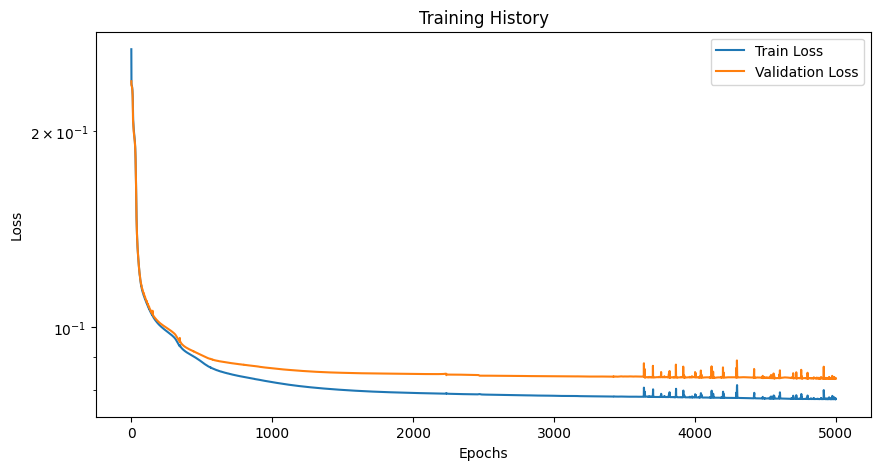

In [ ]:
n_epochs = 1000

checkpoint_file = None  # Path("models/ViT_1070424_4_2_1_2/adam_0.001_mse/epoch_140.pth") # None

if checkpoint_file is not None:
    if not checkpoint_file.exists():
        raise FileNotFoundError(f"Checkpoint file not found: {checkpoint_file}")
    checkpoint = load_checkpoint(checkpoint_file)
    checkpoint.params.n_epochs = n_epochs
    start_epoch = len(checkpoint.results.train_losses) if checkpoint.results is not None else 0
    print(f"Resuming training from epoch {start_epoch}")
    assert start_epoch < checkpoint.params.n_epochs
    
else:
    # initialize a new checkpoint if no checkpoint file is provided
    params = Hyperparameters(
        n_epochs=n_epochs,
        embedding_dims=4,
        query_dims=2,
        n_attention_blocks=1,
        n_attention_heads=2,
        optimizer="adam",
        learning_rate=0.001,
        loss="bce"
    )
    checkpoint = Checkpoint(
        path=None,
        model_state_dict=None,
        optimizer_state_dict=None,
        params=params,
        results=None
    )


checkpoint = optimize(checkpoint)    